# Fase 8a — Inspección de la región de Lima (marzo 2017)

Antes de exportar y rasterizar, **verificamos qué datos hay de verdad**:
1. **Sentinel-1 en Earth Engine** sobre Lima entre feb y abr de 2017: fechas, pasada (ascendente o descendente), órbita y cobertura. Buscamos la escena **más cercana al 18/03/2017** (día de la imagen WorldView-2 de la delineación).
2. **Producto EMSN038 de Copernicus EMS:** qué capas trae (extensión de la inundación, AOI, hidrografía…), en qué CRS y con qué atributos.

**No necesita GPU.** En la autenticación de Earth Engine usa la **cuenta de la UNI** (la dueña del proyecto `rnap-inundaciones`).

## 0. Preparación

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q geopandas pyogrio earthengine-api

Mounted at /content/drive


## 1. Módulo nuevo: `src/lima.py`

In [2]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/lima.py
"""
lima.py
Fase 8: región de prueba de Lima (marzo 2017, El Niño costero).
  - Sentinel-1 GRD desde Google Earth Engine (COPERNICUS/S1_GRD): mismo preprocesamiento que
    Sen1Floods11 (calibración σ0, corrección de terreno, VV/VH en dB, 10 m).
  - Delineación de inundación de Copernicus EMS, activación EMSN038 (WorldView-2, 18 y 21/03/2017).
"""
import zipfile
from pathlib import Path

import pandas as pd
import requests

# Rectángulo de trabajo (lon_min, lat_min, lon_max, lat_max): cuencas bajas de Rímac y Chillón,
# de Carapongo/Cajamarquilla (este) a Puente Piedra/San Martín de Porres (oeste).
# Se refina después con el AOI real del producto EMS.
RECTANGULO_LIMA = [-77.15, -12.08, -76.78, -11.78]

URL_EMSN038 = "https://mapping.emergency.copernicus.eu/download/EMSN038/EMSN038_Geodatabase.zip"


# ----------------------------------------------------------------------------- Earth Engine
def buscar_escenas_s1(ee, rectangulo=RECTANGULO_LIMA, inicio="2017-02-15", fin="2017-04-15") -> pd.DataFrame:
    """Lista las escenas Sentinel-1 IW que tocan el rectángulo: fecha, satélite, órbita y cobertura."""
    region = ee.Geometry.Rectangle(rectangulo)
    coleccion = (ee.ImageCollection("COPERNICUS/S1_GRD")
                 .filterBounds(region).filterDate(inicio, fin)
                 .filter(ee.Filter.eq("instrumentMode", "IW")))

    def describir(imagen):
        interseccion = imagen.geometry().intersection(region, 100).area(100)
        return ee.Feature(None, {
            "id": imagen.id(),
            "fecha_hora": imagen.date().format("YYYY-MM-dd HH:mm"),
            "satelite": imagen.get("platform_number"),
            "pasada": imagen.get("orbitProperties_pass"),
            "orbita_relativa": imagen.get("relativeOrbitNumber_start"),
            "polarizaciones": imagen.get("transmitterReceiverPolarisation"),
            "cobertura_%": interseccion.divide(region.area(100)).multiply(100),
        })

    filas = [f["properties"] for f in coleccion.map(describir).getInfo()["features"]]
    df = pd.DataFrame(filas)
    if df.empty:
        return df
    df["polarizaciones"] = df["polarizaciones"].apply(lambda p: "+".join(p) if isinstance(p, list) else p)
    df["cobertura_%"] = df["cobertura_%"].round(1)
    return df.sort_values("fecha_hora").reset_index(drop=True)


def url_miniatura(ee, id_imagen, banda="VV", rectangulo=RECTANGULO_LIMA, rango=(-25, 0)):
    imagen = ee.Image(f"COPERNICUS/S1_GRD/{id_imagen}").select(banda)
    return imagen.getThumbURL({"region": ee.Geometry.Rectangle(rectangulo), "dimensions": 768,
                               "min": rango[0], "max": rango[1], "format": "png"})


# ----------------------------------------------------------------------------- Copernicus EMS
def descargar_emsn038(dir_destino: Path, url: str = URL_EMSN038) -> Path:
    """Descarga y descomprime el producto vectorial EMSN038. Devuelve la carpeta descomprimida."""
    dir_destino.mkdir(parents=True, exist_ok=True)
    ruta_zip = dir_destino / Path(url).name
    if not ruta_zip.exists():
        respuesta = requests.get(url, timeout=120)
        respuesta.raise_for_status()
        ruta_zip.write_bytes(respuesta.content)
    dir_extraido = dir_destino / ruta_zip.stem
    if not dir_extraido.exists():
        with zipfile.ZipFile(ruta_zip) as z:
            z.extractall(dir_extraido)
    # a veces el zip trae otros zips adentro
    for interno in list(dir_extraido.rglob("*.zip")):
        destino = interno.with_suffix("")
        if not destino.exists():
            with zipfile.ZipFile(interno) as z:
                z.extractall(destino)
    return dir_extraido


def listar_capas_vectoriales(dir_raiz: Path) -> pd.DataFrame:
    """Inventario de todas las capas vectoriales (geodatabase, geojson, shp): nombre, geometría, n° de objetos, CRS, columnas."""
    import geopandas as gpd
    import pyogrio

    fuentes = [f for patron in ("*.gdb", "*.gpkg", "*.geojson", "*.json", "*.shp") for f in dir_raiz.rglob(patron)]
    filas = []
    for fuente in fuentes:
        try:
            capas = pyogrio.list_layers(fuente)
        except Exception:
            continue   # p. ej. un .json de metadatos que no es geográfico
        for nombre, tipo in capas:
            try:
                gdf = gpd.read_file(fuente, layer=nombre)
                filas.append({"fuente": str(fuente.relative_to(dir_raiz)), "capa": nombre, "geometria": tipo,
                              "objetos": len(gdf), "crs": str(gdf.crs),
                              "columnas": ", ".join(c for c in gdf.columns if c != "geometry")})
            except Exception as error:
                filas.append({"fuente": str(fuente.relative_to(dir_raiz)), "capa": nombre, "geometria": tipo,
                              "objetos": f"error: {error}"})
    return pd.DataFrame(filas)


def leer_capa(dir_raiz: Path, fuente_relativa: str, capa: str):
    import geopandas as gpd
    return gpd.read_file(dir_raiz / fuente_relativa, layer=capa)


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/lima.py


## 2. Earth Engine: autenticación
Se abre un enlace: elige la **cuenta de la UNI**, acepta y vuelve.

In [3]:
import ee
ee.Authenticate()
ee.Initialize(project='rnap-inundaciones')
print('Earth Engine listo')

Earth Engine listo


## 3. Escenas Sentinel-1 disponibles sobre Lima
**Qué buscar:** una escena del **18/03/2017** (descendente según la literatura) con **cobertura ~100 %** y polarizaciones **VV+VH**. También veremos la del 17/03 (ascendente) y la del 24/03.

In [4]:
import pandas as pd
from IPython.display import Image, display
from src.configuracion import DIR_RESULTADOS, DIR_FIGURAS
from src.lima import buscar_escenas_s1, url_miniatura, descargar_emsn038, listar_capas_vectoriales, leer_capa, RECTANGULO_LIMA

escenas = buscar_escenas_s1(ee)
escenas.to_csv(DIR_RESULTADOS / 'f8_escenas_s1_lima.csv', index=False)
escenas

,cobertura_%,fecha_hora,id,orbita_relativa,pasada,polarizaciones,satelite
0,100.0,2017-02-22 23:33,S1B_IW_GRDH_1SSV_20170222T233304_20170222T2333...,18,ASCENDING,VV,B
1,88.5,2017-02-26 10:46,S1B_IW_GRDH_1SDV_20170226T104625_20170226T1046...,69,DESCENDING,VV+VH,B
2,97.0,2017-03-05 10:38,S1B_IW_GRDH_1SDV_20170305T103823_20170305T1038...,171,DESCENDING,VV+VH,B
3,100.0,2017-03-06 23:33,S1B_IW_GRDH_1SSV_20170306T233304_20170306T2333...,18,ASCENDING,VV,B
4,88.7,2017-03-10 10:46,S1B_IW_GRDH_1SDV_20170310T104625_20170310T1046...,69,DESCENDING,VV+VH,B
5,97.1,2017-03-17 10:38,S1B_IW_GRDH_1SDV_20170317T103823_20170317T1038...,171,DESCENDING,VV+VH,B
6,100.0,2017-03-18 23:33,S1B_IW_GRDH_1SSV_20170318T233304_20170318T2333...,18,ASCENDING,VV,B
7,100.0,2017-03-24 23:33,S1A_IW_GRDH_1SSV_20170324T233341_20170324T2334...,18,ASCENDING,VV,A
8,97.1,2017-03-29 10:38,S1B_IW_GRDH_1SDV_20170329T103823_20170329T1038...,171,DESCENDING,VV+VH,B
9,100.0,2017-03-30 23:33,S1B_IW_GRDH_1SSV_20170330T233305_20170330T2333...,18,ASCENDING,VV,B


### Vista rápida de la escena más cercana al 18/03/2017 (VV y VH)

In [5]:
objetivo = pd.Timestamp('2017-03-18')
escenas['distancia_dias'] = (pd.to_datetime(escenas['fecha_hora']) - objetivo).dt.total_seconds().abs() / 86400
candidata = escenas.sort_values(['distancia_dias', 'cobertura_%'], ascending=[True, False]).iloc[0]
print(candidata[['id', 'fecha_hora', 'pasada', 'orbita_relativa', 'polarizaciones', 'cobertura_%']])
print('VV'); display(Image(url=url_miniatura(ee, candidata['id'], 'VV', rango=(-25, 0))))
print('VH'); display(Image(url=url_miniatura(ee, candidata['id'], 'VH', rango=(-32, -5))))

id                 S1B_IW_GRDH_1SDV_20170317T103823_20170317T1038...
fecha_hora                                          2017-03-17 10:38
pasada                                                    DESCENDING
orbita_relativa                                                  171
polarizaciones                                                 VV+VH
cobertura_%                                                     97.1
Name: 5, dtype: object
VV


VH


## 4. Producto EMSN038 (Copernicus EMS)
Se guarda en Drive (`datos_lima/emsn038/`), es liviano. Si la descarga directa fallara, descárgalo a mano desde la página de la activación (*Geodatabase*) y súbelo a esa carpeta.

In [6]:
DIR_LIMA = RAIZ_PROYECTO / 'datos_lima'
dir_ems = descargar_emsn038(DIR_LIMA / 'emsn038')
print('Archivos:')
for ruta in sorted(dir_ems.rglob('*')):
    if ruta.is_file() or ruta.suffix == '.gdb':
        print('  ', ruta.relative_to(dir_ems))

Archivos:
   EMSN038_UTM18S_v0.gdb
   EMSN038_UTM18S_v0.gdb/a00000001.TablesByName.atx
   EMSN038_UTM18S_v0.gdb/a00000001.gdbindexes
   EMSN038_UTM18S_v0.gdb/a00000001.gdbtable
   EMSN038_UTM18S_v0.gdb/a00000001.gdbtablx
   EMSN038_UTM18S_v0.gdb/a00000002.gdbtable
   EMSN038_UTM18S_v0.gdb/a00000002.gdbtablx
   EMSN038_UTM18S_v0.gdb/a00000003.gdbindexes
   EMSN038_UTM18S_v0.gdb/a00000003.gdbtable
   EMSN038_UTM18S_v0.gdb/a00000003.gdbtablx
   EMSN038_UTM18S_v0.gdb/a00000004.CatItemsByPhysicalName.atx
   EMSN038_UTM18S_v0.gdb/a00000004.CatItemsByType.atx
   EMSN038_UTM18S_v0.gdb/a00000004.FDO_UUID.atx
   EMSN038_UTM18S_v0.gdb/a00000004.freelist
   EMSN038_UTM18S_v0.gdb/a00000004.gdbindexes
   EMSN038_UTM18S_v0.gdb/a00000004.gdbtable
   EMSN038_UTM18S_v0.gdb/a00000004.gdbtablx
   EMSN038_UTM18S_v0.gdb/a00000004.spx
   EMSN038_UTM18S_v0.gdb/a00000005.CatItemTypesByName.atx
   EMSN038_UTM18S_v0.gdb/a00000005.CatItemTypesByParentTypeID.atx
   EMSN038_UTM18S_v0.gdb/a00000005.CatItemTypesByUUI

In [7]:
inventario = listar_capas_vectoriales(dir_ems)
pd.set_option('display.max_colwidth', 120)
inventario

/usr/local/lib/python3.13/dist-packages/pyogrio/core.py:169: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


,fuente,capa,geometria,objetos,crs,columnas
0,EMSN038_UTM18S_v0.gdb,ElevP,Point,26,EPSG:32718,"FCSubtype, GFID, F_CODE, BEL, ELA, NAM, NFI, NFN, ZVH, ACC, CCN, SDV, SDP, SRT, TXT"
1,EMSN038_UTM18S_v0.gdb,ContourL,MultiLineString,2368,EPSG:32718,"FCSubtype, GFID, F_CODE, HQC, ZVH, ACC, CCN, SDV, SDP, SRT, TXT, SHAPE_Length"
2,EMSN038_UTM18S_v0.gdb,BuiltupP,Point,177,EPSG:32718,"FCSubtype, GFID, F_CODE, BAC, FUC, FUN, NAM, NFI, NFN, ORD, ACC, CCN, SDV, SDP, SRT, TXT"
3,EMSN038_UTM18S_v0.gdb,BridgeL,MultiLineString,0,EPSG:32718,"FCSubtype, GFID, F_CODE, BOT, BSC, FUN, MCC, NAM, NFI, NFN, NOS, OHB, TRS, VOI, WD1, WID, ACC, CCN, SDV, SDP, SRT, T..."
4,EMSN038_UTM18S_v0.gdb,LULC,MultiPolygon,41243,EPSG:32718,"FCSubtype, LULC, NAM, NAM_INFO, TXT, ACC, CCN, SDV, SDP, SRT, LULC_UA_DESC, AREA_HA, SHAPE_Length, SHAPE_Area"
5,EMSN038_UTM18S_v0.gdb,RoadL,MultiLineString,36153,EPSG:32718,"FCSubtype, GFID, F_CODE, CON, FUN, HCT, LOC, LTN, MES, NAM, NFI, NFN, RST, SEP, WD1, WTC, ACC, CCN, SDV, SDP, SRT, T..."
6,EMSN038_UTM18S_v0.gdb,TrailL,MultiLineString,9712,EPSG:32718,"FCSubtype, GFID, F_CODE, NAM, NFI, NFN, WTC, ACC, CCN, SDV, SDP, SRT, TXT, SHAPE_Length"
7,EMSN038_UTM18S_v0.gdb,WatrcrsL,MultiLineString,11157,EPSG:32718,"FCSubtype, GFID, F_CODE, CDA, HYP, LOC, NAM, NFI, NFN, ACC, CCN, SDV, SDP, SRT, TXT, SHAPE_Length"
8,EMSN038_UTM18S_v0.gdb,TrackL,MultiLineString,2064,EPSG:32718,"FCSubtype, GFID, F_CODE, NAM, NFI, NFN, WD1, WTC, ACC, CCN, SDV, SDP, SRT, TXT, buf_wid, SHAPE_Length"
9,EMSN038_UTM18S_v0.gdb,TunnelL,MultiLineString,0,EPSG:32718,"FCSubtype, GFID, F_CODE, FUN, NAM, NFI, NFN, TRS, WID, ACC, CCN, SDV, SDP, SRT, TXT, SHAPE_Length"


### Valores de los atributos categóricos de cada capa de polígonos
Sirve para identificar **qué polígonos son agua de inundación** (p. ej. un campo tipo `obj_type`/`notation` con valores como *Flooded area*, *Flood trace*…) y cuál es el **área mapeada (AOI)**.

In [8]:
capas_poligonos = inventario[inventario['geometria'].astype(str).str.contains('Polygon', na=False)]
for _, fila in capas_poligonos.iterrows():
    gdf = leer_capa(dir_ems, fila['fuente'], fila['capa'])
    print(f"\n=== {fila['fuente']} :: {fila['capa']}  ({len(gdf)} polígonos, CRS {gdf.crs})")
    for columna in gdf.columns.drop('geometry'):
        valores = gdf[columna].dropna().unique()
        if 0 < len(valores) <= 15 and not pd.api.types.is_numeric_dtype(gdf[columna]):
            print(f"   {columna}: {list(valores)}")
    area_km2 = gdf.to_crs(32718).area.sum() / 1e6          # UTM 18S (Lima)
    print(f"   área total: {area_km2:.2f} km²")


=== EMSN038_UTM18S_v0.gdb :: LULC  (41243 polígonos, CRS EPSG:32718)
   NAM_INFO: ['UNK']
   TXT: ['N_A']
   SDP: ['N_A']
   área total: 2416.14 km²

=== EMSN038_UTM18S_v0.gdb :: AerofacA  (1 polígonos, CRS EPSG:32718)
   GFID: [' ']
   F_CODE: ['GB005']
   IKO: ['SPJC']
   NAM: ['Jorge Chávez International Airport']
   SDV: ['N_A']
   SDP: ['N_A']
   TXT: ['N_A']
   área total: 3.70 km²

=== EMSN038_UTM18S_v0.gdb :: BuiltupA  (437 polígonos, CRS EPSG:32718)
   GFID: [' ']
   F_CODE: ['AL020', 'AL208']
   NAM: ['UNK']
   NFI: ['N_A']
   NFN: ['N_A']
   CCN: ['No copyright or restriction of rights of use is asserted by originator of this information.']
   SDV: ['N_A']
   SDP: ['N_A']
   TXT: ['Urban', 'Suburban', 'Rural', 'N_A', 'Industrial']
   área total: 594.40 km²

=== EMSN038_UTM18S_v0.gdb :: MiscpopA  (0 polígonos, CRS EPSG:32718)
   área total: 0.00 km²

=== EMSN038_UTM18S_v0.gdb :: WatrcrsA  (2 polígonos, CRS EPSG:32718)
   GFID: ['A8DFA759-0FBC-4C25-96FD-95AE57CC588B', '69F1C7

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(



=== EMSN038_UTM18S_v0.gdb :: EMSN038_AOI  (1 polígonos, CRS EPSG:32718)
   Name: ['Map']
   descriptio: ['1: 79820\n']
   timestamp: [' ']
   begin: [' ']
   end: [' ']
   altitudeMo: [' ']
   icon: [' ']
   title: ['Map']
   scale: ['79820']
   format: ['A1']
   orientatio: ['landscape']
   área total: 2416.16 km²

=== EMSN038_UTM18S_v0.gdb :: LakeresA  (542 polígonos, CRS EPSG:32718)
   F_CODE: ['BH080']
   NAM: ['UNK']
   NFI: ['OSM']
   NFN: ['N_A']
   CCN: ['No copyright or restriction of rights of use is asserted by originator of this information.']
   SDV: ['N_A']
   SDP: ['N_A']
   TXT: ['water']
   área total: 0.73 km²

=== EMSN038_UTM18S_v0.gdb :: CoastA  (1 polígonos, CRS EPSG:32718)
   GFID: [' ']
   F_CODE: ['BA040']
   NA2: ['UNK']
   NAM: ['UNK']
   NFI: ['N_A']
   NFN: ['N_A']
   CCN: ['No copyright or restriction of rights of use is asserted by originator of this information.']
   SDV: ['N_A']
   SDP: ['N_A']
   TXT: ['N_A']
   área total: 363.74 km²

=== EMSN038_UTM1

/usr/local/lib/python3.13/dist-packages/shapely/measurement.py:48: RuntimeWarning: invalid value encountered in area
  return lib.area(geometry, **kwargs)


   área total: 488071042.07 km²

=== EMSN038_UTM18S_v0.gdb :: DamAssess_A  (1073 polígonos, CRS EPSG:32718)
   source: ['river', 'maximun height']
   área total: 13.58 km²

=== EMSN038_UTM18S_v0.gdb :: Potential_Maximum_flood  (13 polígonos, CRS EPSG:32718)
   source: ['river', 'maximun height']
   área total: 13.58 km²

=== EMSN038_UTM18S_v0.gdb :: Riverbank  (11 polígonos, CRS EPSG:32718)
   source: ['maximun height']
   área total: 7.24 km²

=== EMSN038_UTM18S_v0.gdb :: SAR_LandslideErosionPotential  (2678 polígonos, CRS EPSG:32718)
   área total: 125.30 km²

=== EMSN038_UTM18S_v0.gdb :: grid200  (53376 polígonos, CRS EPSG:32718)
   área total: 2135.04 km²


### Mapa rápido de todas las capas de polígonos

/usr/local/lib/python3.13/dist-packages/geopandas/plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


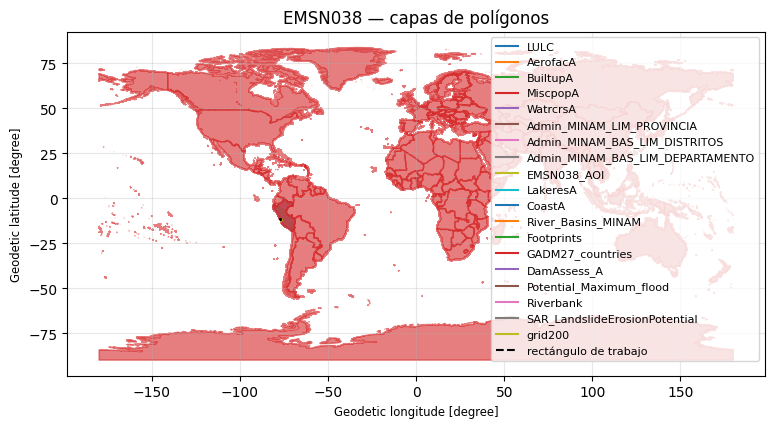

In [9]:
import matplotlib.pyplot as plt
figura, eje = plt.subplots(figsize=(9, 9))
colores = plt.cm.tab10.colors
for i, (_, fila) in enumerate(capas_poligonos.iterrows()):
    gdf = leer_capa(dir_ems, fila['fuente'], fila['capa']).to_crs(4326)
    gdf.plot(ax=eje, facecolor='none' if 'aoi' in fila['capa'].lower() or 'area_of' in fila['capa'].lower() else colores[i % 10],
             edgecolor=colores[i % 10], alpha=0.6, linewidth=1)
    eje.plot([], [], color=colores[i % 10], label=fila['capa'])
x0, y0, x1, y1 = RECTANGULO_LIMA
eje.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], 'k--', label='rectángulo de trabajo')
eje.legend(fontsize=8); eje.set_title('EMSN038 — capas de polígonos'); eje.grid(alpha=0.3)
figura.savefig(DIR_FIGURAS / 'f8_emsn038_capas.png', dpi=150, bbox_inches='tight');

## Para traer a la conversación
La tabla de escenas (3) y las miniaturas VV/VH, el inventario de capas (4), la salida de atributos/áreas y el mapa.
Con eso fijamos la escena y cómo convertir los polígonos en etiqueta (agua / no agua / sin dato) en la fase 8b.

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(



=== EMSN038_AOI: 1 polígonos | área 2416.16 km²
   Name: ['Map']
   descriptio: ['1: 79820\n']
   timestamp: [' ']
   begin: [' ']
   end: [' ']
   altitudeMo: [' ']
   tessellate: [np.float64(-1.0)]
   extrude: [np.float64(0.0)]
   visibility: [np.float64(-1.0)]
   drawOrder: [np.float64(0.0)]
   icon: [' ']
   title: ['Map']
   scale: ['79820']
   format: ['A1']
   orientatio: ['landscape']

=== Footprints: 6 polígonos | área 4648.14 km²
   SDV: [Timestamp('2016-03-27 00:00:00+0000', tz='UTC'), Timestamp('2016-03-20 00:00:00+0000', tz='UTC'), Timestamp('2016-11-16 00:00:00+0000', tz='UTC'), Timestamp('2017-03-21 00:00:00+0000', tz='UTC'), Timestamp('2017-03-18 00:00:00+0000', tz='UTC')]
   SDP: ['SPOT 7', 'WorldView-2']

=== DamAssess_A: 1073 polígonos | área 13.58 km²
   FID_OPTICAL_FloodExtent_OBIA: [np.int32(389), np.int32(394), np.int32(395), np.int32(396), np.int32(397), np.int32(398), np.int32(399), np.int32(400), np.int32(401), np.int32(404), np.int32(405), np.int32(403)] …
 

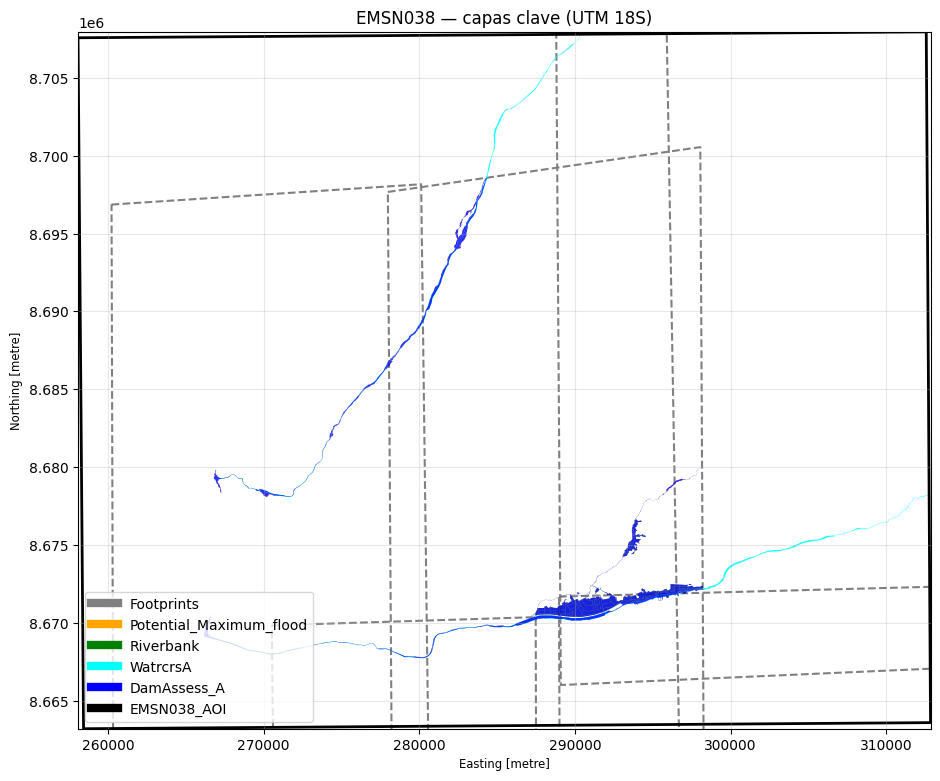

In [10]:
import matplotlib.pyplot as plt
GDB = 'EMSN038_UTM18S_v0.gdb'
capas = ['EMSN038_AOI', 'Footprints', 'DamAssess_A', 'Potential_Maximum_flood', 'Riverbank', 'WatrcrsA']
gdfs = {c: leer_capa(dir_ems, GDB, c) for c in capas}           # todas en UTM 18S (metros)

for c, g in gdfs.items():
    print(f"\n=== {c}: {len(g)} polígonos | área {g.area.sum() / 1e6:.2f} km²")
    for col in g.columns.drop('geometry'):
        if col.lower().startswith('shape'):
            continue
        valores = g[col].dropna().unique()
        print(f"   {col}: {list(valores[:12])}{' …' if len(valores) > 12 else ''}")

estilos = {'Footprints': dict(facecolor='none', edgecolor='gray', linestyle='--', linewidth=1.5),
           'Potential_Maximum_flood': dict(color='orange', alpha=0.3),
           'Riverbank': dict(color='green', alpha=0.5),
           'WatrcrsA': dict(color='cyan', alpha=0.9),
           'DamAssess_A': dict(color='blue', alpha=0.8),
           'EMSN038_AOI': dict(facecolor='none', edgecolor='black', linewidth=2)}
figura, eje = plt.subplots(figsize=(11, 11))
for c, estilo in estilos.items():
    gdfs[c].plot(ax=eje, **estilo)
    eje.plot([], [], color=estilo.get('color', estilo.get('edgecolor')), lw=6, label=c)
x0, y0, x1, y1 = gdfs['EMSN038_AOI'].total_bounds
eje.set_xlim(x0, x1); eje.set_ylim(y0, y1)
eje.legend(loc='lower left'); eje.set_title('EMSN038 — capas clave (UTM 18S)'); eje.grid(alpha=0.3)
figura.savefig(DIR_FIGURAS / 'f8_emsn038_zoom.png', dpi=150, bbox_inches='tight');